# 1.Dilation and Erosion 

### a. Apply dilation and erosion to lung.jpg using 3x3 square shaped structuring element. Before applying dilation and erosion, you must perform the thersholding to make the input image into binary one. Determine the threshold value by yourself. 

영상 크기 (높이, 너비): (290, 372)
밝기 범위: 41 ~ 255


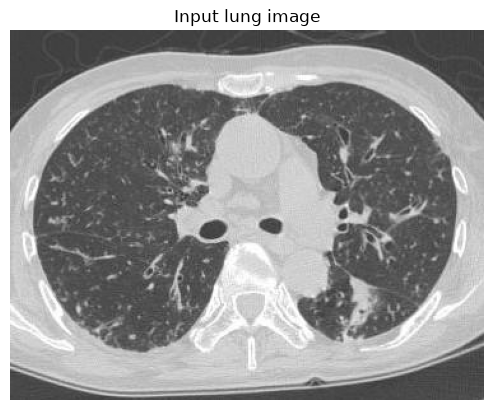

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image_path = Path("handson images") / "lung.jpg"

with Image.open(image_path) as img:
    lung = np.array(img.convert("L"))

print("영상 크기 (높이, 너비):", lung.shape)
print("밝기 범위:", lung.min(), "~", lung.max())

plt.imshow(lung, cmap="gray", vmin=0, vmax=255)
plt.title("Input lung image")
plt.axis("off")
plt.show()

In [2]:
from scipy import ndimage as ndi

# Thresholding
threshold = 110
binary = lung > threshold

# 3×3 square structuring element
se = np.ones((3, 3), dtype=bool)

# Dilation and erosion
dilated = ndi.binary_dilation(binary, structure=se, border_value=0)
eroded = ndi.binary_erosion(binary, structure=se, border_value=1)

### b. Display the results of thresholding, dilation, and erosion. 

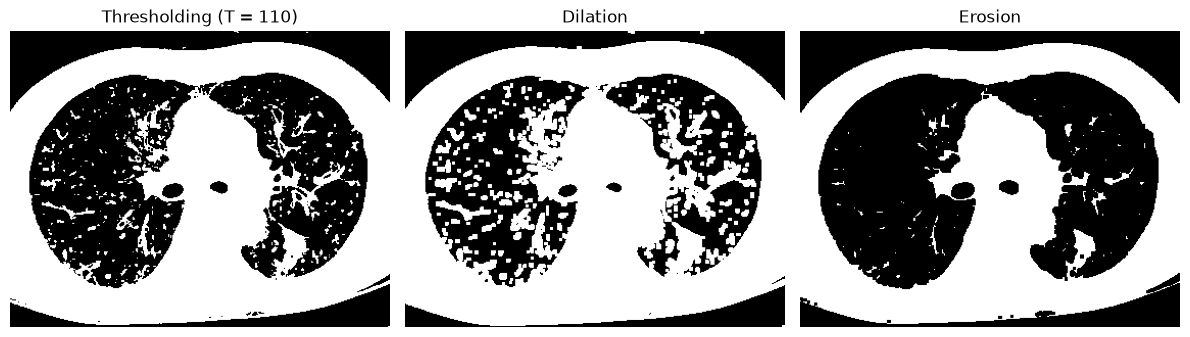

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Thresholding (T = {threshold})")

axes[1].imshow(dilated, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Dilation")

axes[2].imshow(eroded, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Erosion")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### c. Get morphological gradient of the binary image and display it. 

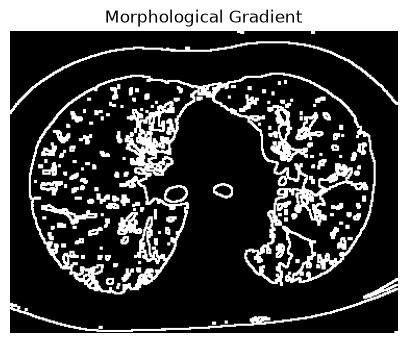

In [4]:
gradient = dilated.astype(int) - eroded.astype(int)

plt.figure(figsize=(5, 4))
plt.imshow(gradient, cmap="gray", vmin=0, vmax=1)
plt.title("Morphological Gradient")
plt.axis("off")
plt.show()

# 2. Noise Removal by Opening and Closing 

### a. Add salt & pepper noise to the binary image you made in 1.a (noise density 0.02).

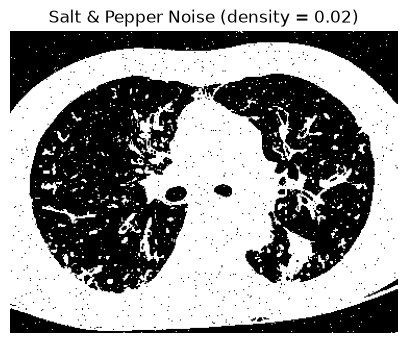

In [5]:
rng = np.random.default_rng(11)
random_values = rng.random(binary.shape)

noisy = binary.copy()
noisy[random_values < 0.01] = True     # Salt: 흰색
noisy[random_values >= 0.99] = False   # Pepper: 검은색

plt.figure(figsize=(5, 4))
plt.imshow(noisy, cmap="gray", vmin=0, vmax=1)
plt.title("Salt & Pepper Noise (density = 0.02)")
plt.axis("off")
plt.show()

### b. Apply morphological operations to remove the noise. 

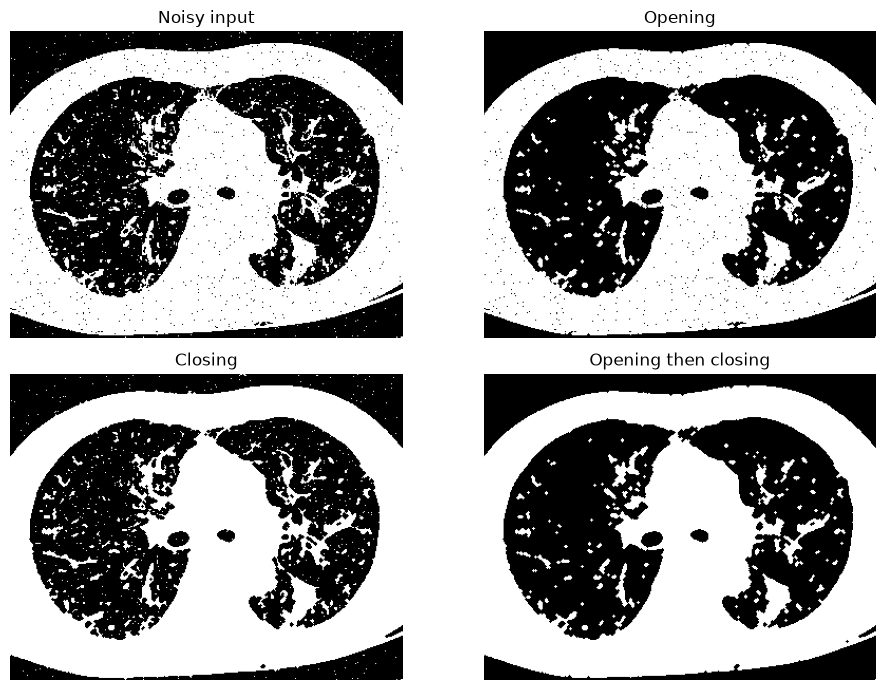

In [6]:
cross = ndi.generate_binary_structure(2, 1)

# 영상 테두리에서 생기는 인공적인 경계를 줄이기 위해 패딩
padded = np.pad(noisy, 4, mode="edge")

opened = ndi.binary_opening(padded, structure=cross)
closed = ndi.binary_closing(padded, structure=cross)
filtered = ndi.binary_closing(opened, structure=cross)

# 패딩을 제거해 원래 영상 크기로 복원
opened = opened[4:-4, 4:-4]
closed = closed[4:-4, 4:-4]
filtered = filtered[4:-4, 4:-4]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, title, image in zip(
    axes.ravel(),
    ["Noisy input", "Opening", "Closing", "Opening then closing"],
    [noisy, opened, closed, filtered],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 3. Lung Segmentation 

Segment the lung regions in lungCT.jpg using thresholding, edge detection, and morphological 
operations. Display the results as shown below. (hint: Since lungCT.jpg is the RGB color image, 
change the lung boundary into red color (255, 0, 0).) 

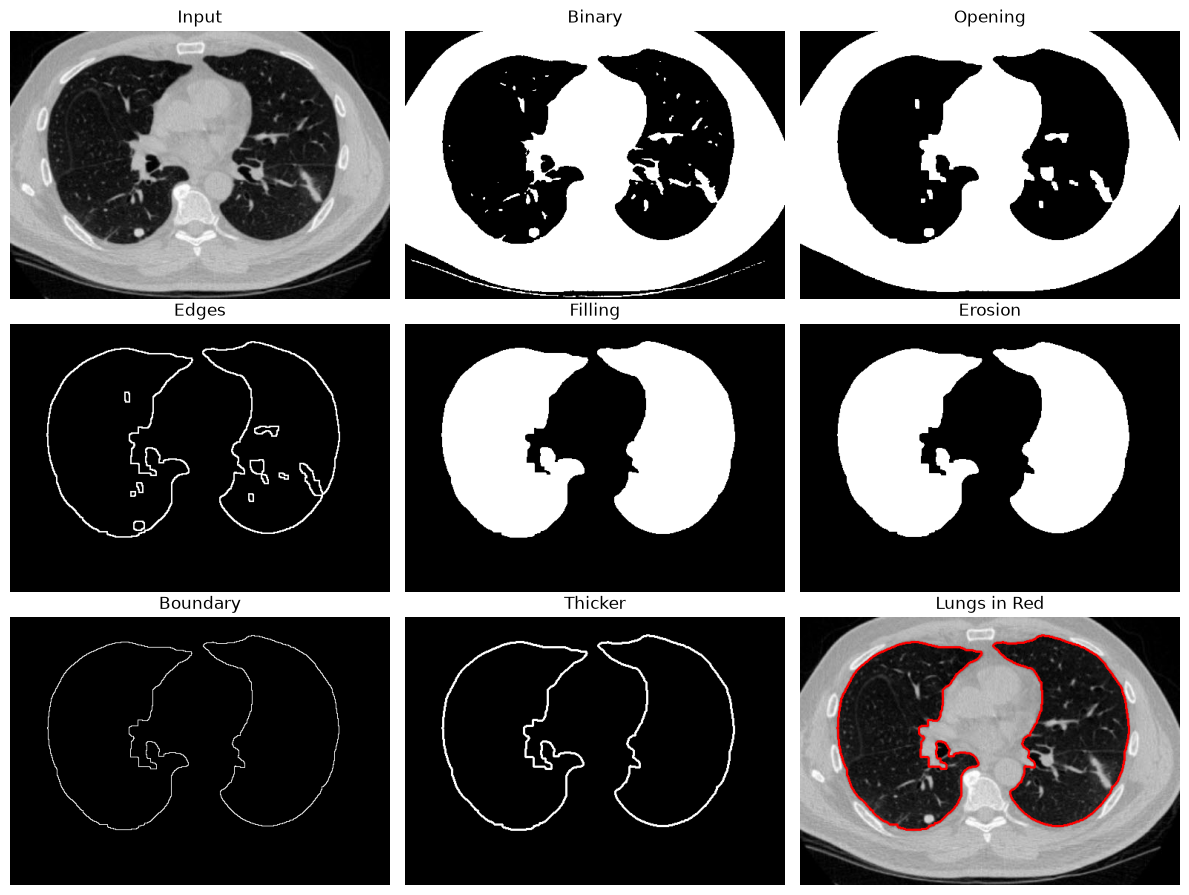

In [7]:
with Image.open(Path("handson images") / "lungCT.jpg") as img:
    ct_rgb = np.array(img.convert("RGB"))
    ct_gray = np.array(img.convert("L"))

# 1. Thresholding과 opening
ct_binary = ct_gray > 85
ct_opened = ndi.binary_opening(
    ct_binary, structure=np.ones((5, 5), dtype=bool)
)

# 2. 어두운 영역을 연결 성분으로 나누고 바깥 공기 제외
labels, _ = ndi.label(~ct_opened)
border_ids = np.unique(np.concatenate([
    labels[0, :], labels[-1, :], labels[:, 0], labels[:, -1]
]))

areas = np.bincount(labels.ravel())
areas[0] = 0
areas[border_ids] = 0

inside_ids = np.flatnonzero(areas)
lung_ids = inside_ids[np.argsort(areas[inside_ids])[-2:]]
lung_candidate = np.isin(labels, lung_ids)

# 3. Morphological gradient로 경계 검출
edges = (
    ndi.binary_dilation(lung_candidate, structure=se)
    & ~ndi.binary_erosion(lung_candidate, structure=se)
)

# 4. 경계 내부를 채운 뒤 폐 마스크와 최종 경계 만들기
filled = ndi.binary_fill_holes(edges)
lung_mask = ndi.binary_erosion(filled, structure=se)
boundary = lung_mask & ~ndi.binary_erosion(lung_mask, structure=se)
thick_boundary = ndi.binary_dilation(boundary, structure=cross)

# 5. 원본 RGB 영상에 빨간색 경계 표시
ct_overlay = ct_rgb.copy()
ct_overlay[thick_boundary] = (255, 0, 0)

fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for ax, title, image in zip(
    axes.ravel(),
    ["Input", "Binary", "Opening", "Edges", "Filling",
     "Erosion", "Boundary", "Thicker", "Lungs in Red"],
    [ct_rgb, ct_binary, ct_opened, edges, filled,
     lung_mask, boundary, thick_boundary, ct_overlay],
):
    if image.ndim == 2:
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    else:
        ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 4. Shape Detection by Fourier descriptor 

입력 binary 영상의 Fourier descriptor(FD)를 구하고 FD 의 구성요소 중 
가장 저주파 coefficients 를 두개 만을 취하여 영상의 shape 을 출력한 후 
입력과 출력 영상의 차이에 대해 논하시오. 
구체적 절차가 필요하면 아래 세부 지시를 따르시오. 본인의 주관대로 
수행해도 상관없습니다.

a. Make the matrix above. Find the position coordinates (x, y) of 
foreground pixels valued '1' and convert them into the complex 
array 'comp'. 
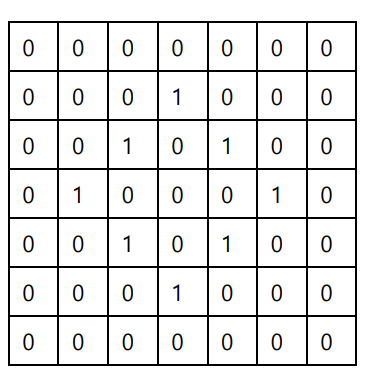

In [12]:
shape_binary = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0],
    [0, 0, 1, 0, 1, 0, 0],
    [0, 1, 0, 0, 0, 1, 0],
    [0, 0, 1, 0, 1, 0, 0],
    [0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0],
])

rows, cols = np.nonzero(shape_binary)

# x는 오른쪽으로, y는 위쪽으로 증가하는 1부터 시작하는 좌표
x = cols + 1
y = shape_binary.shape[0] - rows

# np.nonzero()가 찾은 순서를 그대로 유지
comp = x + 1j * y

print("comp =", comp)

comp = [4.+6.j 3.+5.j 5.+5.j 2.+4.j 6.+4.j 3.+3.j 5.+3.j 4.+2.j]


b. Do Fourier transform with ‘comp’ and save the result to ‘ft’. 

In [13]:
ft = np.fft.fft(comp)

print("ft =", np.round(ft, 3))

ft = [32.   +32.j     4.243 +3.414j  2.    +2.j    -2.586 +3.414j
  8.    +4.j    -4.243 +0.586j -2.    +2.j    -5.414 +0.586j]


c. Make zero vector ‘ft1’ which has same size of ‘ft’ and save only first and second element value 
of ‘ft’ to ‘ft’1. 

In [14]:
ft1 = np.zeros_like(ft)
ft1[:2] = ft[:2]

print("ft1 =", np.round(ft1, 3))

ft1 = [32.   +32.j     4.243 +3.414j  0.    +0.j     0.    +0.j
  0.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j   ]


d. Do inverse transform of ‘ft1’ and display the results by plotting imaginary numbers. 

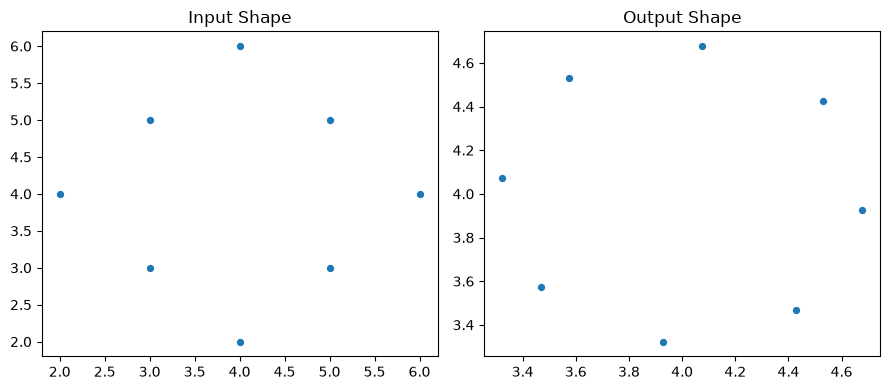

In [15]:
reconstructed = np.fft.ifft(ft1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

# 실수부를 x좌표, 허수부를 y좌표로 표시
axes[0].scatter(comp.real, comp.imag, s=18)
axes[0].set_title("Input Shape")

axes[1].scatter(reconstructed.real, reconstructed.imag, s=18)
axes[1].set_title("Output Shape")

plt.tight_layout()
plt.show()

# 5. Color Image Processing 

'PET_noise.jpg' 파일의 노이즈를 제거하고 입력과 출력 영상을 보이시오. 

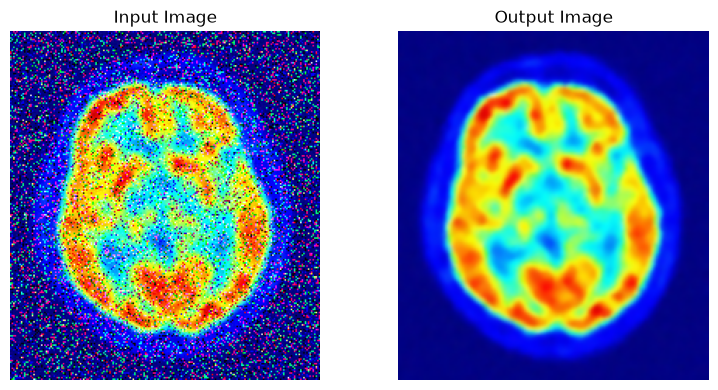

In [16]:
with Image.open(Path("handson images") / "pet_noise.jpg") as img:
    pet_rgb = np.array(img.convert("RGB"))

# RGB 채널별로 5×5 median filter 적용
pet_median = ndi.median_filter(pet_rgb, size=(5, 5, 1))

# 공간 방향으로만 Gaussian smoothing 적용
pet_smooth = ndi.gaussian_filter(
    pet_median.astype(float), sigma=(1, 1, 0)
)
pet_filtered = np.rint(pet_smooth).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(pet_rgb)
axes[0].set_title("Input Image")

axes[1].imshow(pet_filtered)
axes[1].set_title("Output Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 6. K-Mean Clustering for Color Images 

flower.jpg, flowers-white.jpg 영상에 대해 k-mean clustering 을 수행하여 꽃을 segment 하시오. 
,  값을 바꾸어가며 적용하여 최적의 영상을 얻으시오 

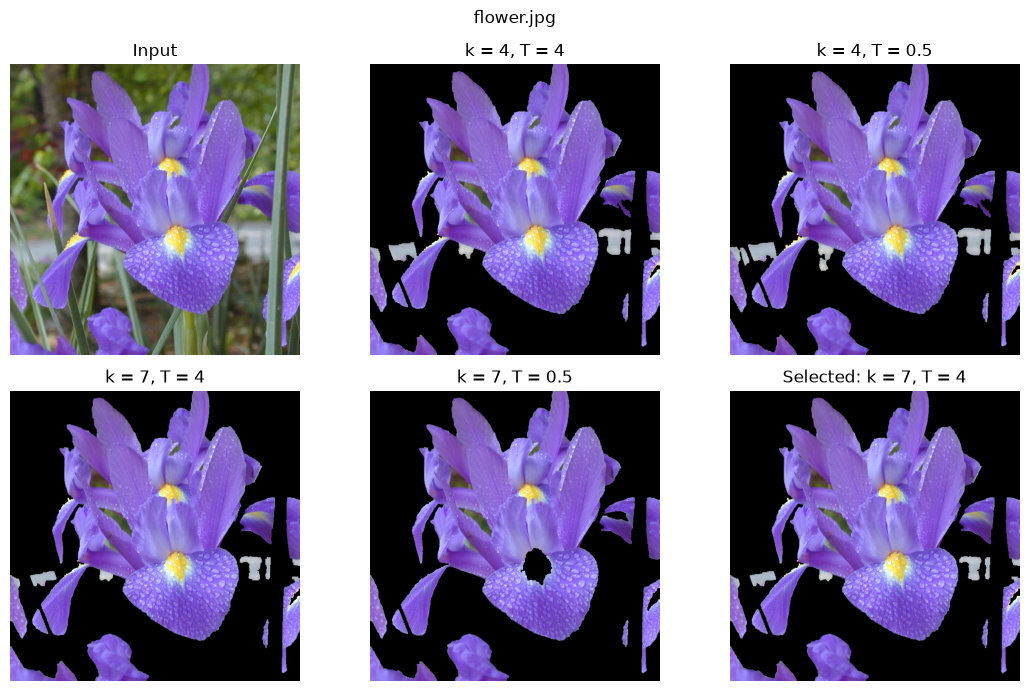

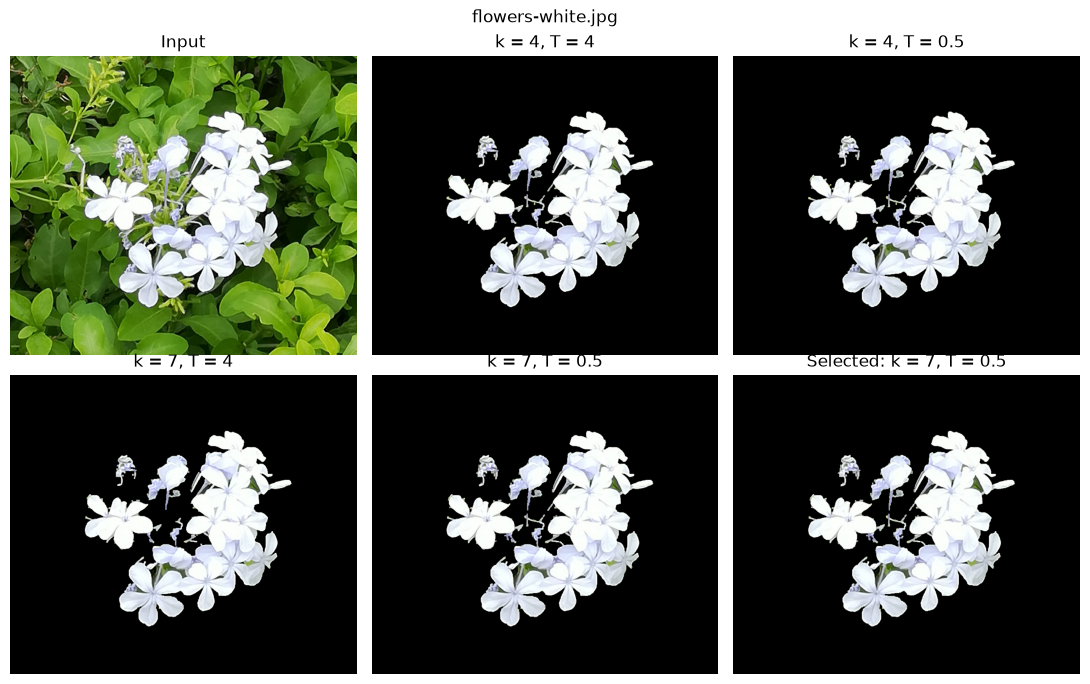

In [17]:
def fit_rgb_kmeans(samples, k, tolerance):
    rng = np.random.default_rng(11)
    best_loss = np.inf
    best_centers = None

    # 초기 중심에 따른 차이를 줄이기 위해 3번 실행
    for _ in range(3):
        centers = samples[rng.choice(len(samples), k, replace=False)].copy()

        for _ in range(100):
            distances = ((samples[:, None] - centers) ** 2).sum(axis=2)
            labels = distances.argmin(axis=1)

            new_centers = centers.copy()
            for cluster in range(k):
                members = samples[labels == cluster]
                if len(members) > 0:
                    new_centers[cluster] = members.mean(axis=0)
                else:
                    new_centers[cluster] = samples[rng.integers(len(samples))]

            movement = np.linalg.norm(new_centers - centers, axis=1).max()
            centers = new_centers
            if movement <= tolerance:
                break

        distances = ((samples[:, None] - centers) ** 2).sum(axis=2)
        loss = distances.min(axis=1).mean()
        if loss < best_loss:
            best_loss = loss
            best_centers = centers

    return best_centers


settings = [(4, 4.0), (4, 0.5), (7, 4.0), (7, 0.5)]
selected_settings = {
    "flower.jpg": (7, 4.0),
    "flowers-white.jpg": (7, 0.5),
}

for filename, selected in selected_settings.items():
    with Image.open(Path("handson images") / filename) as img:
        rgb = np.array(img.convert("RGB"))

    pixels = rgb.reshape(-1, 3).astype(np.float32)

    # 최대 10,000개 픽셀로 중심을 계산한 뒤, 전체 픽셀을 분류
    rng = np.random.default_rng(11)
    indices = rng.choice(len(pixels), min(len(pixels), 10_000), replace=False)
    samples = pixels[indices]

    fig, axes = plt.subplots(2, 3, figsize=(11, 7))
    axes = axes.ravel()
    axes[0].imshow(rgb)
    axes[0].set_title("Input")

    for ax, (k, tolerance) in zip(axes[1:5], settings):
        centers = fit_rgb_kmeans(samples, k, tolerance)
        distances = ((pixels[:, None] - centers) ** 2).sum(axis=2)
        labels = distances.argmin(axis=1).reshape(rgb.shape[:2])
        r, g, b = centers.T

        # 보라색 꽃잎 또는 밝은 흰색 꽃잎에 해당하는 cluster 선택
        if filename == "flower.jpg":
            is_flower = (b - g > 20) & (r - g > 2)
        else:
            is_flower = (centers.min(axis=1) > 145) & (b >= g - 18)

        mask = is_flower[labels]

        # 작은 조각과 꽃잎 내부의 작은 구멍 정리
        mask = ndi.binary_closing(mask, structure=se, border_value=1)
        mask = ndi.binary_opening(mask, structure=se)

        components, _ = ndi.label(mask)
        sizes = np.bincount(components.ravel())
        sizes[0] = 0
        mask = sizes[components] >= 0.001 * mask.size

        holes = ndi.binary_fill_holes(mask) & ~mask
        hole_labels, _ = ndi.label(holes)
        hole_sizes = np.bincount(hole_labels.ravel())
        mask |= holes & (hole_sizes[hole_labels] <= 0.006 * mask.size)

        segmented = np.where(mask[..., None], rgb, 0)
        ax.imshow(segmented)
        ax.set_title(f"k = {k}, T = {tolerance:g}")

        if (k, tolerance) == selected:
            axes[5].imshow(segmented)
            axes[5].set_title(f"Selected: k = {k}, T = {tolerance:g}")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(filename)
    plt.tight_layout()
    plt.show()

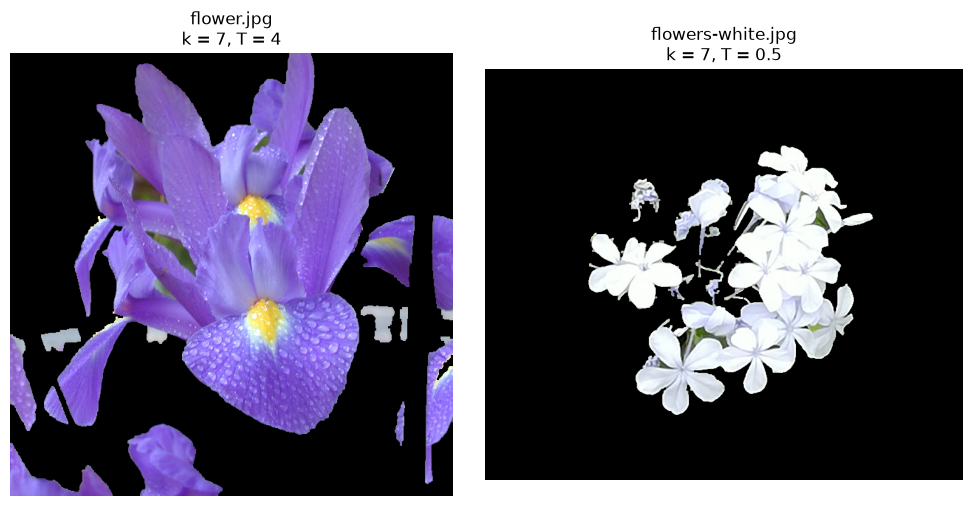

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (filename, (k, tolerance)) in zip(axes, selected_settings.items()):
    with Image.open(Path("handson images") / filename) as img:
        rgb = np.array(img.convert("RGB"))

    pixels = rgb.reshape(-1, 3).astype(np.float32)
    rng = np.random.default_rng(11)
    indices = rng.choice(len(pixels), min(len(pixels), 10_000), replace=False)

    centers = fit_rgb_kmeans(pixels[indices], k, tolerance)
    distances = ((pixels[:, None] - centers) ** 2).sum(axis=2)
    labels = distances.argmin(axis=1).reshape(rgb.shape[:2])

    r, g, b = centers.T
    if filename == "flower.jpg":
        is_flower = (b - g > 20) & (r - g > 2)
    else:
        is_flower = (centers.min(axis=1) > 145) & (b >= g - 18)

    mask = is_flower[labels]
    mask = ndi.binary_closing(mask, structure=se, border_value=1)
    mask = ndi.binary_opening(mask, structure=se)

    components, _ = ndi.label(mask)
    sizes = np.bincount(components.ravel())
    sizes[0] = 0
    mask = sizes[components] >= 0.001 * mask.size

    holes = ndi.binary_fill_holes(mask) & ~mask
    hole_labels, _ = ndi.label(holes)
    hole_sizes = np.bincount(hole_labels.ravel())
    mask |= holes & (hole_sizes[hole_labels] <= 0.006 * mask.size)

    ax.imshow(np.where(mask[..., None], rgb, 0))
    ax.set_title(f"{filename}\nk = {k}, T = {tolerance:g}")
    ax.axis("off")

plt.tight_layout()
plt.show()